# 08 · Test-set report

Full evaluation of one trained model on the **test split** of the dataset in `.env`. It covers metrics, charts and example predictions.
Everything is saved to `results/test_report_<run>/`: the figures (PNG) and `metrics.json`.

Predictions are filtered with **the app's thresholds** (`backend/app/config.py`: leaf ≥ 0.5, diseases ≥ 0.4), so the numbers describe what users get.

| Section | What it answers |
|---|---|
| 1. Coverage error | How wrong is the "X % diseased" number the app shows? (main metric) |
| 2. Severity | How often does the mild / moderate / severe class come out right? |
| 3. Presence | Does the model notice the disease at all, and how many false alarms? |
| 4. Pixel metrics | How good are the masks: precision, recall, F1 (Dice), IoU per class |
| 5. Threshold sweep | Would a different disease threshold be better? |
| 6. Instance metrics | Standard mAP (for papers; the app doesn't need separate lesions) |
| 7. Examples | Pictures: best, typical and worst images |

All rates come with **bootstrap 95 % confidence intervals** over test images. With few images per disease, the intervals matter as much as the point values.

In [1]:
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from dotenv import load_dotenv
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from PIL import Image
from pycocotools.coco import COCO

from eval_utils import (CLASSES, DISEASES, confusion, coverage_primary_leaf, image_coverage, lins_ccc, load_predictor,
                        paint_class_map, severity)

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")
DATA_VERSION = f"v{os.environ['ROBOFLOW_VERSION']}"
DATA_NAME = f"{os.environ['ROBOFLOW_PROJECT']}-{DATA_VERSION}"

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

- `RUN`: the run folder to evaluate (`yolo26x-seg_data-v2` = the Nov 4 run).
- `TEST_PROJECT` / `TEST_VERSION`: the dataset whose **test split** is scored, independent of the model, e.g. `"lds_test", 1` for the fixed test set. It is downloaded on first use. The defaults come from `.env`.
- `LEAF_CONF` / `DISEASE_CONF`: the app's thresholds. `SWEEP` lists the disease thresholds tried in section 5.

In [2]:
from eval_utils import ensure_dataset

RUN = ROOT / "runs" / "yolo26x-seg_data-v2"
CHECKPOINT = RUN / "weights" / "best.pt"
TEST_PROJECT, TEST_VERSION = os.environ["ROBOFLOW_PROJECT"], int(os.environ["ROBOFLOW_VERSION"])  # e.g. "lds_test", 1
TEST_NAME = f"{TEST_PROJECT}-v{TEST_VERSION}"
coco_dir, YOLO_DATA = ensure_dataset(ROOT, TEST_PROJECT, TEST_VERSION, os.environ["ROBOFLOW_API_KEY"],
                                     os.environ["ROBOFLOW_WORKSPACE"])
TEST_DIR = coco_dir / "test"
LEAF_CONF = 0.5  # backend leaf_confidence
DISEASE_CONF = 0.4  # backend disease_confidence
SWEEP = (0.2, 0.3, 0.4, 0.5, 0.6, 0.7)
N_BOOT = 1000
SEED = 0

OUT = ROOT / "results" / f"test_report_{RUN.name}" / TEST_NAME
OUT.mkdir(parents=True, exist_ok=True)
print("test data:", TEST_NAME, "| checkpoint:", CHECKPOINT.relative_to(ROOT), "| output:", OUT.relative_to(ROOT))

# Chart style: light surface, recessive grid and axes, colour-blind-checked palette
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, fixed order
CLASS_COLOR = {"leaf": SERIES[0], "leaf_spot": SERIES[1], "powdery_mildew": SERIES[2]}
METRIC_COLOR = {"precision": SERIES[0], "recall": SERIES[1], "f1": SERIES[2], "iou": SERIES[3]}
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
MISSED, FALSE = "#d03b3b", "#fab219"  # status colours: critical = missed disease, warning = false disease
LABEL = {"leaf": "leaf", "leaf_spot": "leaf spot", "powdery_mildew": "powdery mildew", "background": "background"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def show_table(title, header, rows):
    rows = [[f"{v:.3f}" if isinstance(v, float) else str(v) for v in r] for r in rows]
    widths = [max(len(x) for x in col) for col in zip(header, *rows)]
    print(f"\n{title}")
    print("  ".join(h.ljust(w) for h, w in zip(header, widths)))
    print("  ".join("-" * w for w in widths))
    for r in rows:
        print("  ".join(x.ljust(w) for x, w in zip(r, widths)))


def end_labels(ax, x, items, min_gap):
    # Direct labels at the right end of lines, pushed apart so they never overlap: items = [(y, text)]
    placed = []
    for y, text in sorted(items):
        y = max(y, placed[-1] + min_gap) if placed else y
        placed.append(y)
        ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=8,
                    annotation_clip=False)


def label_bars(ax, bars, fmt="{:.2f}"):
    for b in bars:
        h = b.get_height()
        if np.isfinite(h):
            ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h), xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7.5, color=INK2)

test data: lds_v1-v2 | checkpoint: runs\yolo26x-seg_data-v2\weights\best.pt | output: results\test_report_yolo26x-seg_data-v2\lds_v1-v2


## Ground truth

Per test image: the class map (leaves first, diseases painted on top), image-level coverage (disease % of all leaf pixels) and the primary-leaf coverage (largest leaf, the backend rule).

In [3]:
coco = COCO(str(TEST_DIR / "_annotations.coco.json"))
cat_names = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
images = coco.loadImgs(coco.getImgIds())

gt = []
for img in images:
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img["id"]))
    masks = [coco.annToMask(a).astype(bool) for a in anns]
    names = [cat_names[a["category_id"]] for a in anns]
    cmap = paint_class_map(masks, names, (img["height"], img["width"]))
    gt.append({"map": cmap, "cov": image_coverage(cmap), "leaf_cov": coverage_primary_leaf(masks, names)})

n_inst = {c: len(coco.getAnnIds(catIds=[cid])) for cid, c in cat_names.items() if coco.getAnnIds(catIds=[cid])}
print(f"{len(images)} test images | labelled instances: {n_inst}")
for d in DISEASES:
    print(f"  {LABEL[d]:<15} present in {sum(1 for g in gt if g['cov'] and g['cov'][d] > 0)} images")

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


76 test images | labelled instances: {'leaf': 1480, 'leaf_spot': 3061, 'powdery_mildew': 794}
  leaf spot       present in 70 images
  powdery mildew  present in 23 images


## Predict

One forward pass per image (all detections ≥ 0.01). For every disease threshold in `SWEEP`, it then keeps the leaves at ≥ `LEAF_CONF` and the diseases at ≥ that threshold, and stores a small summary: a 4×4 pixel confusion matrix and the coverage. Time per image is the median after one warm-up image.

In [4]:
kind, predict, model = load_predictor(CHECKPOINT, cat_names)
THRESHOLDS = sorted(set(SWEEP) | {DISEASE_CONF})

recs, times = [], []
for img, g in zip(images, gt):
    image = Image.open(TEST_DIR / img["file_name"]).convert("RGB")
    torch.cuda.synchronize(); t0 = time.perf_counter()
    masks, names, conf = predict(image)
    torch.cuda.synchronize(); times.append(time.perf_counter() - t0)
    rec = {"conf": {}, "cov": {}}
    for thr in THRESHOLDS:
        keep = conf >= np.where(names == "leaf", LEAF_CONF, thr)
        pmap = paint_class_map(masks[keep], names[keep], g["map"].shape)
        rec["conf"][thr] = confusion(g["map"], pmap)
        rec["cov"][thr] = image_coverage(pmap)
        if thr == DISEASE_CONF:
            rec["map"] = pmap
            rec["leaf_cov"] = coverage_primary_leaf(masks[keep], names[keep])
    recs.append(rec)

MS_PER_IMAGE = 1000 * float(np.median(times[1:]))
print(f"{kind}: {len(recs)} images, {MS_PER_IMAGE:.0f} ms per image (GPU, incl. post-processing)")
del model, predict
torch.cuda.empty_cache()

yolo: 76 images, 193 ms per image (GPU, incl. post-processing)


## Metric functions and bootstrap

- **Pixel metrics** come from one confusion matrix summed over the chosen images. Precision = how much of what was predicted as the class is right; recall = how much of the class was found; F1 = Dice.
- **Image metrics** per disease:
  - presence (disease predicted / labelled on the image at all);
  - coverage error in percentage points (pp), over all images and over the images that **have** the disease;
  - bias (+ = over-reports);
  - R², Lin's CCC (agreement), and severity accuracy (none / mild < 5 % / moderate < 25 % / severe).
- **Bootstrap:** the test images are resampled `N_BOOT` times, with the same resamples for every metric. The 95 % CI is the 2.5–97.5 percentile.

In [5]:
def pixel_metrics(cm):
    tp = np.diag(cm).astype(float)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    out = {}
    for i, c in enumerate(CLASSES):
        p = tp[i] / (tp[i] + fp[i]) if tp[i] + fp[i] else np.nan
        r = tp[i] / (tp[i] + fn[i]) if tp[i] + fn[i] else np.nan
        out[c] = {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0,
                  "iou": tp[i] / (tp[i] + fp[i] + fn[i]) if tp[i] + fp[i] + fn[i] else np.nan}
    out["accuracy"] = tp.sum() / cm.sum()
    out["miou"] = np.nanmean([out[c]["iou"] for c in CLASSES[1:]])
    out["mf1"] = np.nanmean([out[c]["f1"] for c in CLASSES[1:]])
    return out


def sev(pct):
    # Backend bands (backend/app/coverage.py): none at 0 %, then eval_utils' mild / moderate / severe
    return "none" if pct <= 0 else severity(pct)


def coverage_pairs(idx, thr, d, level="cov"):
    pred = (lambda i: recs[i]["cov"][thr]) if level == "cov" else (lambda i: recs[i]["leaf_cov"])
    pairs = [(gt[i][level][d], pred(i)[d]) for i in idx if gt[i][level] and pred(i)]
    return np.array(pairs, float).reshape(-1, 2).T


def image_metrics(idx, thr, level="cov"):
    out = {}
    for d in DISEASES:
        g_, p_ = coverage_pairs(idx, thr, d, level)
        has_g, has_p = g_ > 0, p_ > 0
        tp, fp, fn = int((has_g & has_p).sum()), int((~has_g & has_p).sum()), int((has_g & ~has_p).sum())
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        err = p_ - g_
        var = ((g_ - g_.mean()) ** 2).sum()
        out[d] = {
            "presence_precision": prec, "presence_recall": rec,
            "presence_f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0, "tp_fp_fn": [tp, fp, fn],
            "mae": np.abs(err).mean(), "rmse": np.sqrt((err ** 2).mean()), "bias": err.mean(),
            "mae_pos": np.abs(err[has_g]).mean() if has_g.any() else np.nan,
            "bias_pos": err[has_g].mean() if has_g.any() else np.nan,
            "r2": 1 - (err ** 2).sum() / var if var else np.nan, "ccc": lins_ccc(g_, p_),
            "severity_acc": float(np.mean([sev(a) == sev(b) for a, b in zip(g_, p_)])),
            "n": len(g_), "n_pos": int(has_g.sum()),
        }
    return out


n = len(gt)
ALL = np.arange(n)
rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, n, n) for _ in range(N_BOOT)]
CM = {thr: [r["conf"][thr] for r in recs] for thr in THRESHOLDS}

pix = pixel_metrics(sum(CM[DISEASE_CONF]))
img_m = image_metrics(ALL, DISEASE_CONF)
leaf_m = image_metrics(ALL, DISEASE_CONF, level="leaf_cov")
pix_boot = [pixel_metrics(sum(CM[DISEASE_CONF][i] for i in b)) for b in BOOT]
img_boot = [image_metrics(b, DISEASE_CONF) for b in BOOT]


def ci(values):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    return tuple(np.percentile(v, [2.5, 97.5])) if len(v) else (np.nan, np.nan)


def with_ci(point, boots):
    lo, hi = ci(boots)
    return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

## 1. Coverage error: the number the app shows

Main metric: **MAE on images that have the disease** (all-image MAE looks better than it is, because most images have little or no disease), together with **bias** (systematically too low or too high).
Image level = disease % of all leaf pixels in the photo. Primary leaf = largest leaf only, the backend's rule (unstable on multi-leaf photos: a different "largest leaf" changes the number).

In [6]:
rows = []
for key, label in [("mae_pos", "MAE, images with disease (pp)"), ("bias_pos", "bias, images with disease (pp)"),
                   ("mae", "MAE, all images (pp)"), ("rmse", "RMSE, all images (pp)"), ("bias", "bias, all images (pp)"),
                   ("r2", "R²"), ("ccc", "Lin's CCC")]:
    rows.append([label] + [with_ci(img_m[d][key], [b[d][key] for b in img_boot]) for d in DISEASES])
rows.append(["images (with disease)"] + [f"{img_m[d]['n']} ({img_m[d]['n_pos']})" for d in DISEASES])
show_table("Image-level coverage, point [95 % CI]", ["metric"] + [LABEL[d] for d in DISEASES], rows)

show_table("Primary-leaf coverage (backend rule)", ["metric"] + [LABEL[d] for d in DISEASES],
           [[label] + [leaf_m[d][key] for d in DISEASES]
            for key, label in [("mae_pos", "MAE, images with disease (pp)"), ("bias_pos", "bias, images with disease (pp)"),
                               ("mae", "MAE, all images (pp)"), ("ccc", "Lin's CCC")]])


Image-level coverage, point [95 % CI]
metric                          leaf spot               powdery mildew        
------------------------------  ----------------------  ----------------------
MAE, images with disease (pp)   0.483 [0.341, 0.659]    1.146 [0.677, 1.684]  
bias, images with disease (pp)  -0.074 [-0.312, 0.112]  -0.241 [-0.956, 0.462]
MAE, all images (pp)            0.449 [0.310, 0.609]    0.347 [0.169, 0.561]  
RMSE, all images (pp)           0.800 [0.485, 1.155]    0.921 [0.495, 1.298]  
bias, all images (pp)           -0.064 [-0.284, 0.107]  -0.073 [-0.289, 0.124]
R²                              0.910 [0.846, 0.960]    0.944 [0.809, 0.979]  
Lin's CCC                       0.955 [0.912, 0.981]    0.971 [0.883, 0.989]  
images (with disease)           76 (70)                 76 (23)               

Primary-leaf coverage (backend rule)
metric                          leaf spot  powdery mildew
------------------------------  ---------  --------------
MAE, images with 

### Predicted vs true coverage, and Bland–Altman

Left: each dot is one test image; on the dotted line the prediction is exact. Right: error against size. The solid line is the bias, the dashed lines the 95 % limits of agreement (bias ± 1.96 SD). A tilt means the error grows with severity.

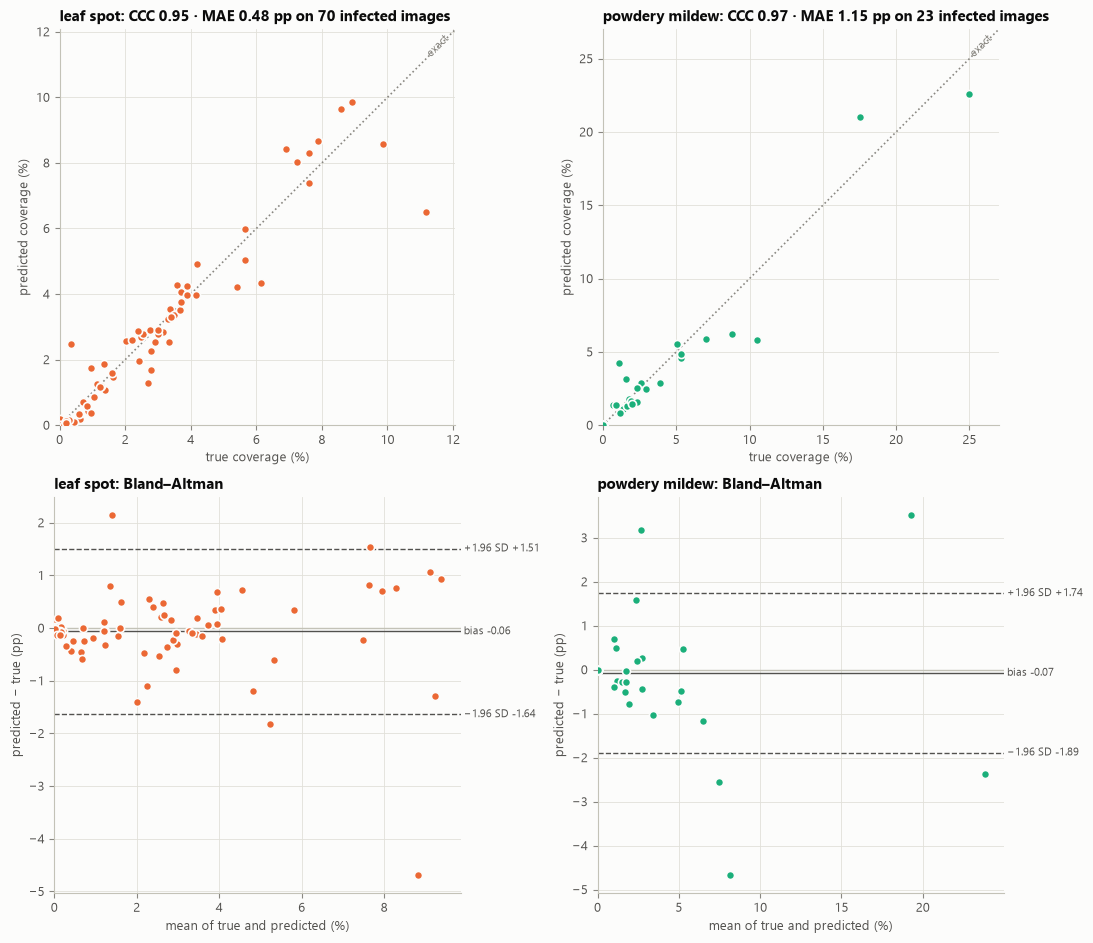

In [7]:
fig, axes = plt.subplots(2, len(DISEASES), figsize=(11, 9.5))
for col, d in enumerate(DISEASES):
    g_, p_ = coverage_pairs(ALL, DISEASE_CONF, d)
    m = img_m[d]
    ax = axes[0][col]
    hi = max(g_.max(), p_.max(), 1) * 1.08
    ax.plot([0, hi], [0, hi], ":", color=MUTED, linewidth=1.2)
    ax.scatter(g_, p_, s=34, color=CLASS_COLOR[d], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.set(xlim=(0, hi), ylim=(0, hi), xlabel="true coverage (%)", ylabel="predicted coverage (%)", aspect="equal")
    ax.set_title(f"{LABEL[d]}: CCC {m['ccc']:.2f} · MAE {m['mae_pos']:.2f} pp on {m['n_pos']} infected images")
    ax.text(0.97 * hi, 0.99 * hi, "exact", color=MUTED, ha="right", va="top", fontsize=8, rotation=45, rotation_mode="anchor")

    ax = axes[1][col]
    mean, diff = (g_ + p_) / 2, p_ - g_
    bias, loa = diff.mean(), 1.96 * diff.std(ddof=1)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.scatter(mean, diff, s=34, color=CLASS_COLOR[d], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    xmax = max(mean.max(), 1) * 1.05
    for y, style, text in [(bias, "-", f"bias {bias:+.2f}"), (bias + loa, "--", f"+1.96 SD {bias + loa:+.2f}"),
                           (bias - loa, "--", f"−1.96 SD {bias - loa:+.2f}")]:
        ax.axhline(y, color=INK2, linestyle=style, linewidth=1)
        ax.text(xmax, y, f" {text}", color=INK2, va="center", fontsize=8)
    ax.set(xlim=(0, xmax), xlabel="mean of true and predicted (%)", ylabel="predicted − true (pp)")
    ax.set_title(f"{LABEL[d]}: Bland–Altman")
fig.tight_layout()
fig.savefig(OUT / "coverage_scatter_bland_altman.png")
plt.show()

## 2. Severity class

The app's bands: **none** 0 %, **mild** < 5 %, **moderate** 5–25 %, **severe** ≥ 25 %. Rows are the truth and columns the prediction; the diagonal is correct.

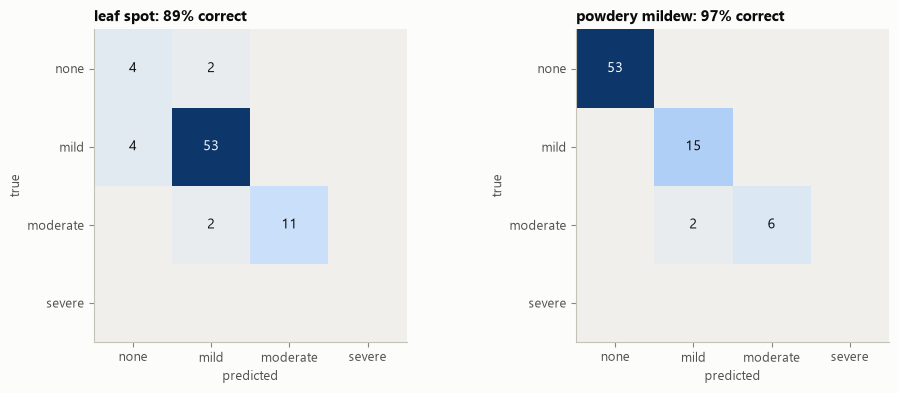


Severity accuracy, point [95 % CI]
disease         accuracy            
--------------  --------------------
leaf spot       0.895 [0.816, 0.961]
powdery mildew  0.974 [0.934, 1.000]


In [8]:
SEV = ["none", "mild", "moderate", "severe"]
fig, axes = plt.subplots(1, len(DISEASES), figsize=(10, 4))
sev_rows = []
for ax, d in zip(axes, DISEASES):
    g_, p_ = coverage_pairs(ALL, DISEASE_CONF, d)
    mat = np.zeros((4, 4), int)
    for a, b in zip(g_, p_):
        mat[SEV.index(sev(a)), SEV.index(sev(b))] += 1
    ax.imshow(mat, cmap=BLUES, vmin=0, vmax=max(mat.max(), 1))
    for i in range(4):
        for j in range(4):
            if mat[i, j]:
                ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=10,
                        color="#ffffff" if mat[i, j] > 0.55 * mat.max() else INK)
    ax.set(xticks=range(4), yticks=range(4), xticklabels=SEV, yticklabels=SEV, xlabel="predicted", ylabel="true")
    ax.grid(False)
    ax.set_title(f"{LABEL[d]}: {img_m[d]['severity_acc']:.0%} correct")
    sev_rows.append([LABEL[d], with_ci(img_m[d]["severity_acc"], [b[d]["severity_acc"] for b in img_boot])])
fig.tight_layout()
fig.savefig(OUT / "severity_confusion.png")
plt.show()
show_table("Severity accuracy, point [95 % CI]", ["disease", "accuracy"], sev_rows)

## 3. Presence: does the model notice the disease?

Per image: is any of the disease predicted, and is any labelled? **Recall** = infected images caught (a miss means the user does nothing); **precision** = alarms that are real.

In [9]:
rows = []
for d in DISEASES:
    m = img_m[d]
    tp, fp, fn = m["tp_fp_fn"]
    rows.append([LABEL[d], with_ci(m["presence_precision"], [b[d]["presence_precision"] for b in img_boot]),
                 with_ci(m["presence_recall"], [b[d]["presence_recall"] for b in img_boot]),
                 with_ci(m["presence_f1"], [b[d]["presence_f1"] for b in img_boot]), tp, fp, fn, m["n"] - tp - fp - fn])
show_table("Presence per image, point [95 % CI]",
           ["disease", "precision", "recall", "F1", "caught", "false alarm", "missed", "correct no"], rows)


Presence per image, point [95 % CI]
disease         precision             recall                F1                    caught  false alarm  missed  correct no
--------------  --------------------  --------------------  --------------------  ------  -----------  ------  ----------
leaf spot       0.971 [0.925, 1.000]  0.943 [0.884, 0.986]  0.957 [0.917, 0.986]  66      2            4       4         
powdery mildew  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  23      0            0       53        


## 4. Pixel metrics per class: mask quality

These explain the coverage numbers. If precision > recall, the model marks too little (coverage under-reported); if recall > precision, too much.


Pixel level, point [95 % CI]
class                   precision             recall                F1 (Dice)             IoU                 
----------------------  --------------------  --------------------  --------------------  --------------------
background              0.873 [0.843, 0.900]  0.916 [0.890, 0.938]  0.894 [0.874, 0.913]  0.808 [0.776, 0.840]
leaf                    0.942 [0.926, 0.956]  0.915 [0.896, 0.932]  0.928 [0.916, 0.940]  0.866 [0.844, 0.888]
leaf spot               0.810 [0.782, 0.832]  0.762 [0.714, 0.804]  0.785 [0.754, 0.812]  0.646 [0.605, 0.684]
powdery mildew          0.703 [0.627, 0.784]  0.632 [0.542, 0.712]  0.666 [0.598, 0.739]  0.499 [0.426, 0.586]
mean (leaf + diseases)                                              0.793 [0.766, 0.821]  0.671 [0.638, 0.705]

pixel accuracy 0.911


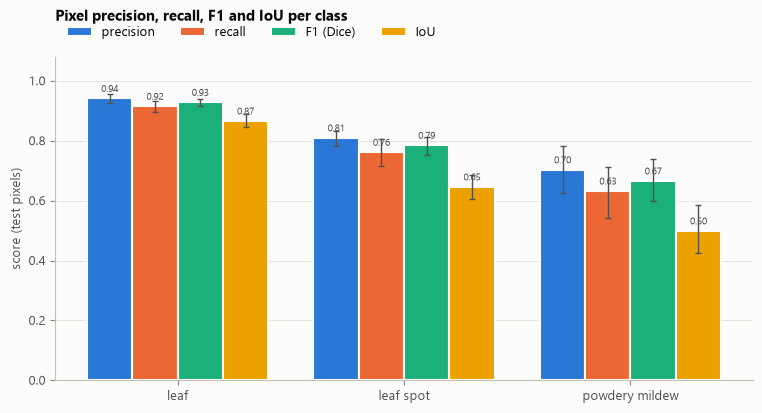

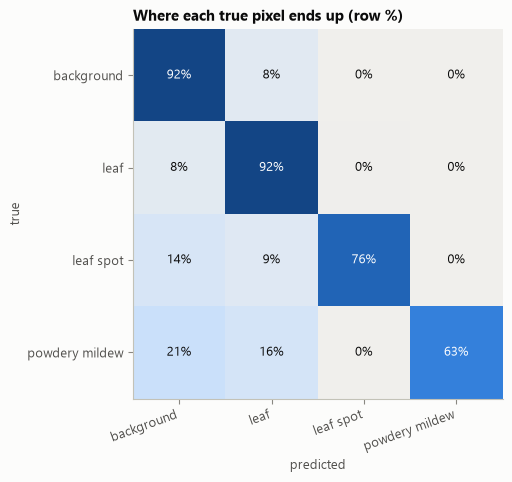

In [10]:
rows = [[LABEL[c]] + [with_ci(pix[c][k], [b[c][k] for b in pix_boot]) for k in ("precision", "recall", "f1", "iou")]
        for c in CLASSES]
rows.append(["mean (leaf + diseases)", "", "", with_ci(pix["mf1"], [b["mf1"] for b in pix_boot]),
             with_ci(pix["miou"], [b["miou"] for b in pix_boot])])
show_table("Pixel level, point [95 % CI]", ["class", "precision", "recall", "F1 (Dice)", "IoU"], rows)
print(f"\npixel accuracy {pix['accuracy']:.3f}")

# Grouped bars: classes on x, the four metrics as series, 95 % CI whiskers, values labelled
fg = CLASSES[1:]
keys = ("precision", "recall", "f1", "iou")
x = np.arange(len(fg))
w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.2))
for j, k in enumerate(keys):
    vals = np.array([pix[c][k] for c in fg])
    lo_hi = np.array([ci([b[c][k] for b in pix_boot]) for c in fg])
    bars = ax.bar(x + (j - 1.5) * w, vals, w, color=METRIC_COLOR[k], edgecolor=SURFACE, linewidth=1.5,
                  label={"f1": "F1 (Dice)", "iou": "IoU"}.get(k, k), zorder=2)
    ax.errorbar(x + (j - 1.5) * w, vals, yerr=np.abs(lo_hi.T - vals), fmt="none", ecolor=INK2, elinewidth=1,
                capsize=2, zorder=3)
    label_bars(ax, bars)
ax.set(xticks=x, xticklabels=[LABEL[c] for c in fg], ylim=(0, 1.08), ylabel="score (test pixels)")
ax.grid(axis="x", visible=False)
ax.legend(ncols=4, loc="upper left", bbox_to_anchor=(0, 1.13))
ax.set_title("Pixel precision, recall, F1 and IoU per class", pad=26)
fig.savefig(OUT / "pixel_metrics.png")
plt.show()

# Pixel confusion, rows normalised: the diagonal is recall; off-diagonal shows where each class goes
cm = sum(CM[DISEASE_CONF]).astype(float)
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(cm_norm, cmap=BLUES, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="#ffffff" if cm_norm[i, j] > 0.55 else INK)
ticks = [LABEL[c] for c in CLASSES]
ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xticklabels=ticks, yticklabels=ticks,
       xlabel="predicted", ylabel="true")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(False)
ax.set_title("Where each true pixel ends up (row %)")
fig.savefig(OUT / "pixel_confusion.png")
plt.show()

## 5. Disease threshold sweep

The same predictions with the disease threshold set from 0.2 to 0.7 (leaves stay at `LEAF_CONF`). Top: pixel metrics. Bottom: coverage error on infected images.
Pick the threshold where the **bias is closest to 0** without precision dropping much. The current app value is marked.


Threshold sweep
threshold  spot P  spot R  spot IoU  spot MAE+  spot bias+  mildew P  mildew R  mildew IoU  mildew MAE+  mildew bias+
---------  ------  ------  --------  ---------  ----------  --------  --------  ----------  -----------  ------------
0.2        0.766   0.834   0.664     0.539      0.352       0.635     0.747     0.522       1.534        1.120       
0.3        0.791   0.801   0.661     0.461      0.132       0.675     0.692     0.519       1.208        0.385       
0.4 (app)  0.810   0.762   0.646     0.483      -0.074      0.703     0.632     0.499       1.146        -0.241      
0.5        0.835   0.704   0.618     0.486      -0.361      0.730     0.554     0.460       1.177        -0.869      
0.6        0.847   0.645   0.578     0.649      -0.599      0.816     0.446     0.405       2.091        -1.954      
0.7        0.860   0.544   0.500     0.993      -0.975      0.837     0.313     0.295       2.934        -2.843      


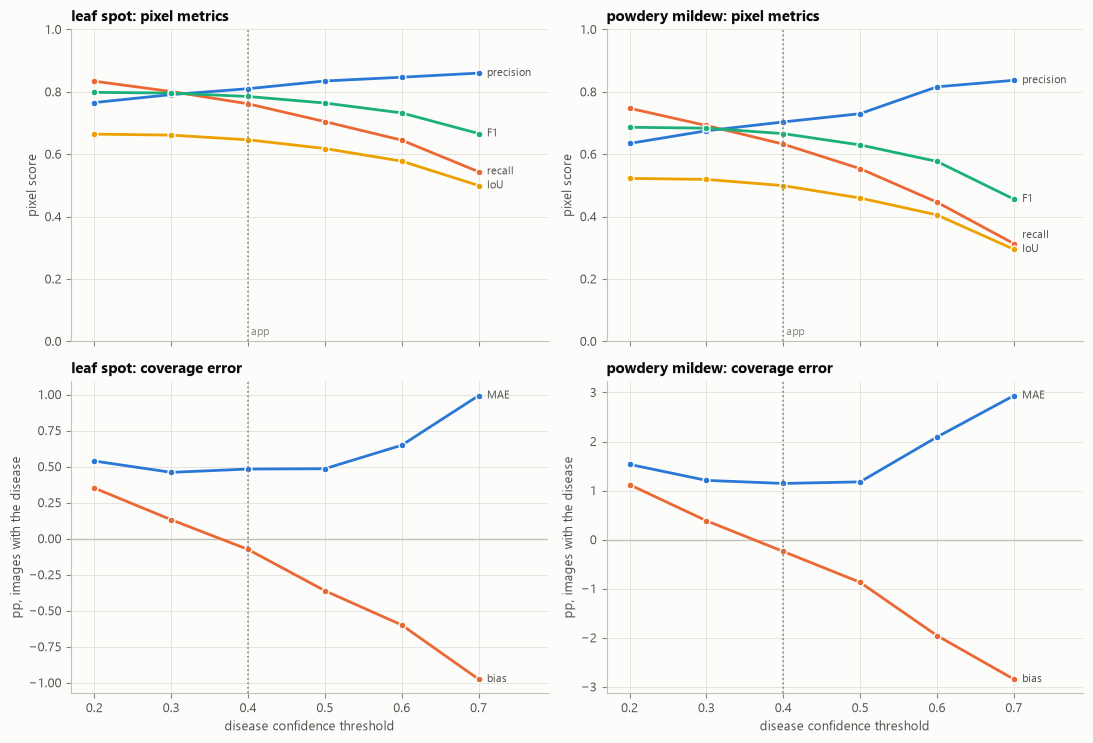

In [11]:
sweep = {thr: (pixel_metrics(sum(CM[thr])), image_metrics(ALL, thr)) for thr in SWEEP}
rows = []
for thr, (p, im) in sweep.items():
    rows.append([f"{thr:.1f}" + (" (app)" if thr == DISEASE_CONF else "")] +
                [v for d in DISEASES for v in (p[d]["precision"], p[d]["recall"], p[d]["iou"], im[d]["mae_pos"], im[d]["bias_pos"])])
show_table("Threshold sweep", ["threshold"] + [f"{s} {k}" for s in ("spot", "mildew")
                                                for k in ("P", "R", "IoU", "MAE+", "bias+")], rows)

fig, axes = plt.subplots(2, len(DISEASES), figsize=(11, 7.5), sharex=True)
for col, d in enumerate(DISEASES):
    ax = axes[0][col]
    ends = []
    for k in ("precision", "recall", "f1", "iou"):
        ys = [sweep[t][0][d][k] for t in SWEEP]
        ax.plot(SWEEP, ys, marker="o", markersize=5, color=METRIC_COLOR[k], markeredgecolor=SURFACE)
        ends.append((ys[-1], {"f1": "F1", "iou": "IoU"}.get(k, k)))
    end_labels(ax, SWEEP[-1], ends, 0.045)
    ax.set(ylim=(0, 1), ylabel="pixel score")
    ax.set_title(f"{LABEL[d]}: pixel metrics")
    ax = axes[1][col]
    ax.axhline(0, color=AXIS, linewidth=1)
    ends = []
    for k, color, text in (("mae_pos", SERIES[0], "MAE"), ("bias_pos", SERIES[1], "bias")):
        ys = [sweep[t][1][d][k] for t in SWEEP]
        ax.plot(SWEEP, ys, marker="o", markersize=5, color=color, markeredgecolor=SURFACE)
        ends.append((ys[-1], text))
    end_labels(ax, SWEEP[-1], ends, 0.06 * np.ptp(ax.get_ylim()))
    ax.set(xlabel="disease confidence threshold", ylabel="pp, images with the disease")
    ax.set_title(f"{LABEL[d]}: coverage error")
    for a in (axes[0][col], ax):
        a.axvline(DISEASE_CONF, color=MUTED, linestyle=":", linewidth=1.2)
    axes[0][col].text(DISEASE_CONF, 0.02, " app", color=MUTED, fontsize=8)
    for a in (axes[0][col], ax):
        a.set_xlim(SWEEP[0] - 0.03, SWEEP[-1] + 0.09)
fig.tight_layout()
fig.savefig(OUT / "threshold_sweep.png")
plt.show()

## 6. Instance metrics (Ultralytics, test split)

Standard detection and segmentation scores: each lesion and leaf must be found as its own object. Report these in a paper for comparability. The app only needs pixel coverage, so two touching lesions predicted as one mask cost mAP but not accuracy in the app.

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)


YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 226.3±42.2 MB/s, size: 147.9 KB)


val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\labels... 41 images, 0 backgrounds, 0 corrupt: 53% ━━━━━━────── 41/76 115.3it/s 0.1s<0.3s

val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\labels... 76 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 450.3it/s 0.2s

val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\images\IMG_1859_JPG_jpg.rf.583dea12d8bb2b6db239b65a86f310a0.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\images\IMG_1865_JPG_jpg.rf.8d8c269ba13f5b143da031c7df26091d.jpg: 2 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\images\IMG_1871_JPG_jpg.rf.08711becbf17be23e63177f43ca35ef8.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\test\images\IMG_1933_JPG_jpg.rf.f0c0898f3f339cb3258b36b18864dca6.jpg: 1 duplicate labels removed


... (10 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.0it/s 3.3s

                   all         76       5330      0.756      0.627      0.679      0.441      0.715      0.562      0.594      0.343


Speed: 0.4ms preprocess, 19.7ms inference, 0.0ms loss, 1.7ms postprocess per image



Instance level (test split)
class           type  precision  recall  F1     mAP50  mAP50-95
--------------  ----  ---------  ------  -----  -----  --------
leaf            box   0.767      0.643   0.700  0.674  0.553   
leaf            mask  0.786      0.632   0.701  0.664  0.532   
leaf spot       box   0.827      0.673   0.742  0.763  0.436   
leaf spot       mask  0.743      0.572   0.646  0.644  0.297   
powdery mildew  box   0.672      0.565   0.614  0.598  0.336   
powdery mildew  mask  0.616      0.481   0.540  0.472  0.200   
all             box   0.756      0.627          0.679  0.441   
all             mask  0.715      0.562          0.594  0.343   


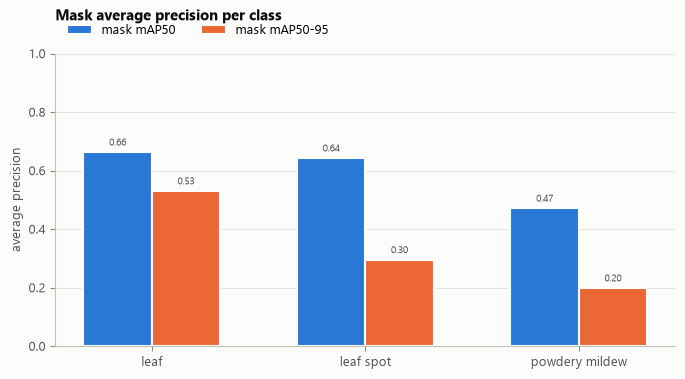

In [12]:
from ultralytics import YOLO

val = YOLO(CHECKPOINT).val(data=str(YOLO_DATA), split="test", imgsz=1024, batch=8, workers=0, verbose=False, plots=False)
inst = {}
for j, c in enumerate(val.ap_class_index):
    name = val.names[int(c)]
    inst[name] = {}
    for kind_, res in (("box", val.box), ("mask", val.seg)):
        p, r, ap50, ap = (float(v) for v in res.class_result(j))
        inst[name][kind_] = {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0,
                             "map50": ap50, "map50_95": ap}
inst["all"] = {k: {"precision": float(res.mp), "recall": float(res.mr), "map50": float(res.map50), "map50_95": float(res.map)}
               for k, res in (("box", val.box), ("mask", val.seg))}

rows = [[LABEL.get(c, c), k] + [v.get(m, "") for m in ("precision", "recall", "f1", "map50", "map50_95")]
        for c, kinds in inst.items() for k, v in kinds.items()]
show_table("Instance level (test split)", ["class", "type", "precision", "recall", "F1", "mAP50", "mAP50-95"], rows)

classes_i = [c for c in inst if c != "all"]
x = np.arange(len(classes_i))
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, (k, label) in enumerate((("map50", "mask mAP50"), ("map50_95", "mask mAP50-95"))):
    bars = ax.bar(x + (j - 0.5) * 0.32, [inst[c]["mask"][k] for c in classes_i], 0.32, color=SERIES[j],
                  edgecolor=SURFACE, linewidth=1.5, label=label, zorder=2)
    label_bars(ax, bars)
ax.set(xticks=x, xticklabels=[LABEL.get(c, c) for c in classes_i], ylim=(0, 1), ylabel="average precision")
ax.grid(axis="x", visible=False)
ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, 1.14))
ax.set_title("Mask average precision per class", pad=24)
fig.savefig(OUT / "instance_map.png")
plt.show()

## 7. Examples

Per row: the photo, the labels, the prediction (app thresholds) and an **error map**.
- Error map colours: green/orange-coloured = disease found correctly; **red** = labelled disease the model missed; **yellow** = disease predicted where there is none; grey = leaf.
- Rows are chosen automatically: the images with the most mildew and the most leaf spot, the worst mildew and leaf-spot errors, and a typical (median-error) image.

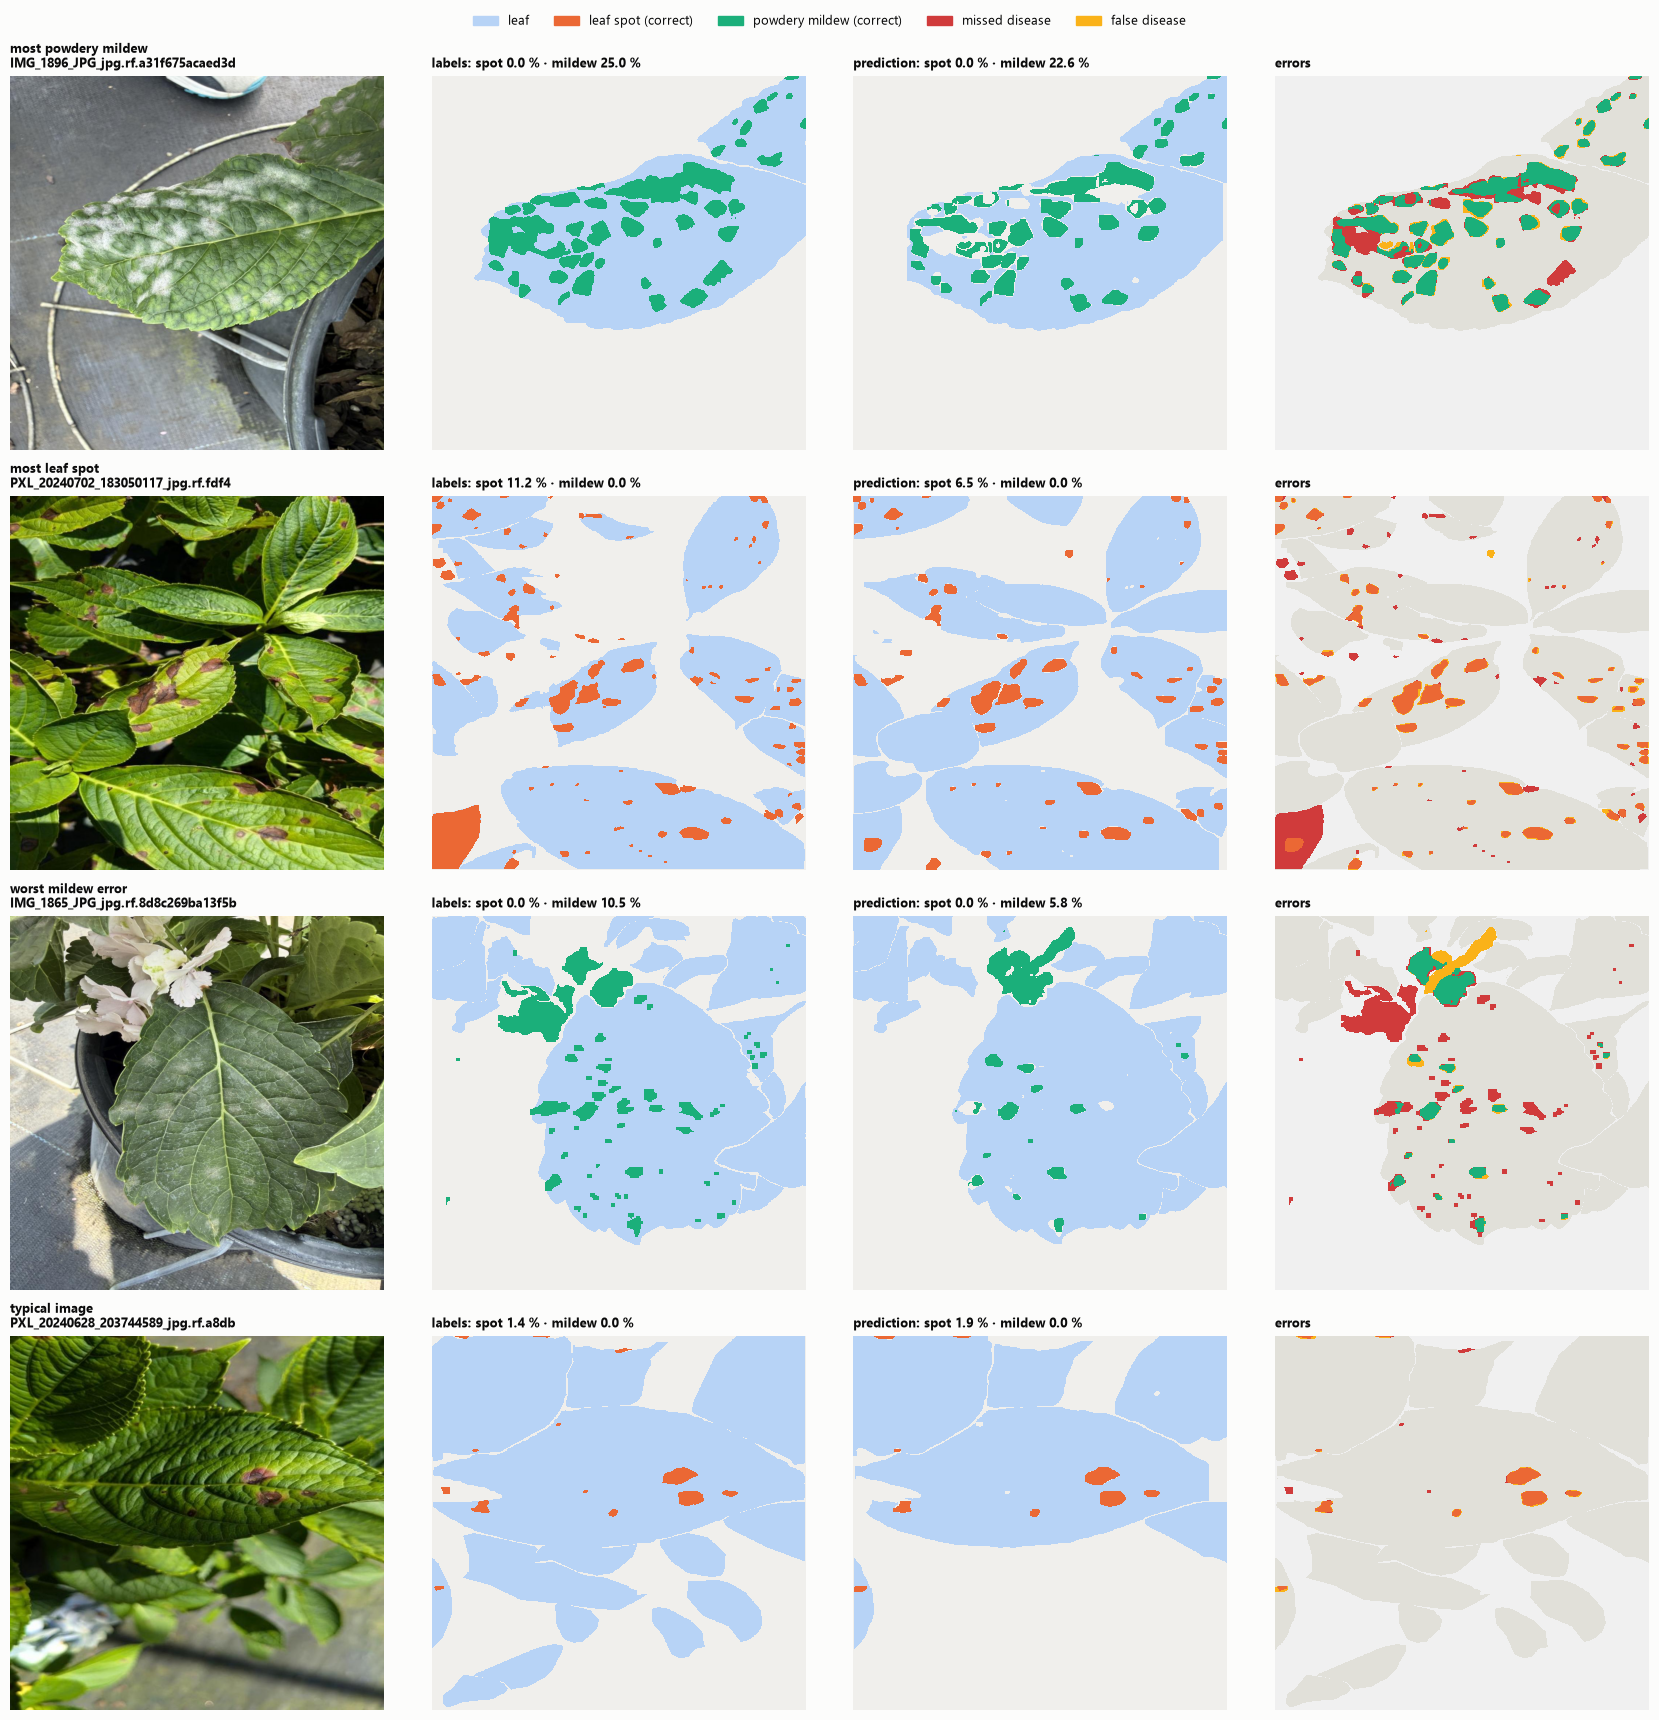

In [13]:
def pick_examples():
    picks = []
    err = {d: [] for d in DISEASES}
    for i, (g, r) in enumerate(zip(gt, recs)):
        c = r["cov"][DISEASE_CONF]
        for d in DISEASES:
            err[d].append(abs(c[d] - g["cov"][d]) if g["cov"] and c else -1)
    by_true = lambda d: max(range(n), key=lambda i: (gt[i]["cov"] or {d: 0})[d])
    for label, i in [("most powdery mildew", by_true("powdery_mildew")), ("most leaf spot", by_true("leaf_spot")),
                     ("worst mildew error", int(np.argmax(err["powdery_mildew"]))),
                     ("worst leaf-spot error", int(np.argmax(err["leaf_spot"]))),
                     ("typical image", int(np.argsort(np.array(err["leaf_spot"]) + np.array(err["powdery_mildew"]))[n // 2]))]:
        if i not in [p for _, p in picks]:
            picks.append((label, i))
    return picks


MAP_COLORS = ListedColormap(["#f0efec", "#b7d3f6", CLASS_COLOR["leaf_spot"], CLASS_COLOR["powdery_mildew"]])
SPOT, MILDEW = CLASSES.index("leaf_spot"), CLASSES.index("powdery_mildew")


def error_map(g_map, p_map):
    rgb = np.full(g_map.shape + (3,), 0xf0, np.uint8)
    rgb[(g_map > 0) | (p_map > 0)] = (0xe1, 0xe0, 0xd9)  # leaf area
    hexrgb = lambda h: tuple(int(h[k:k + 2], 16) for k in (1, 3, 5))
    for cls, d in ((SPOT, "leaf_spot"), (MILDEW, "powdery_mildew")):
        rgb[(g_map == cls) & (p_map == cls)] = hexrgb(CLASS_COLOR[d])
    disease_g, disease_p = g_map >= SPOT, p_map >= SPOT
    rgb[disease_g & (p_map != g_map)] = hexrgb(MISSED)  # labelled disease not found (or the other disease)
    rgb[disease_p & ~disease_g] = hexrgb(FALSE)  # disease predicted on healthy leaf or background
    return rgb


def cov_text(c):
    return "no leaf" if not c else f"spot {c['leaf_spot']:.1f} % · mildew {c['powdery_mildew']:.1f} %"


EXAMPLES = pick_examples()
fig, axes = plt.subplots(len(EXAMPLES), 4, figsize=(17, 4.3 * len(EXAMPLES)), squeeze=False)
for row, (why, i) in zip(axes, EXAMPLES):
    g_map, p_map = gt[i]["map"], recs[i]["map"]
    row[0].imshow(Image.open(TEST_DIR / images[i]["file_name"]).convert("RGB"))
    row[0].set_title(f"{why}\n{images[i]['file_name'][:34]}", fontsize=9)
    row[1].imshow(g_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    row[1].set_title(f"labels: {cov_text(gt[i]['cov'])}", fontsize=9)
    row[2].imshow(p_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    row[2].set_title(f"prediction: {cov_text(recs[i]['cov'][DISEASE_CONF])}", fontsize=9)
    row[3].imshow(error_map(g_map, p_map), interpolation="nearest")
    row[3].set_title("errors", fontsize=9)
    for ax in row:
        ax.axis("off")
handles = [Patch(color="#b7d3f6", label="leaf"), Patch(color=CLASS_COLOR["leaf_spot"], label="leaf spot (correct)"),
           Patch(color=CLASS_COLOR["powdery_mildew"], label="powdery mildew (correct)"),
           Patch(color=MISSED, label="missed disease"), Patch(color=FALSE, label="false disease")]
fig.legend(handles=handles, loc="upper center", ncols=5, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(OUT / "examples.png", dpi=110)
plt.show()

## 8. Your own photos (no labels)

Runs the model on any photos with the app's thresholds and shows what the app would report:
- **leaf** = largest leaf, the backend rule;
- **image** = all leaf pixels in the photo.

Without labels there is no accuracy here, only the prediction. Add paths to `PHOTOS`.

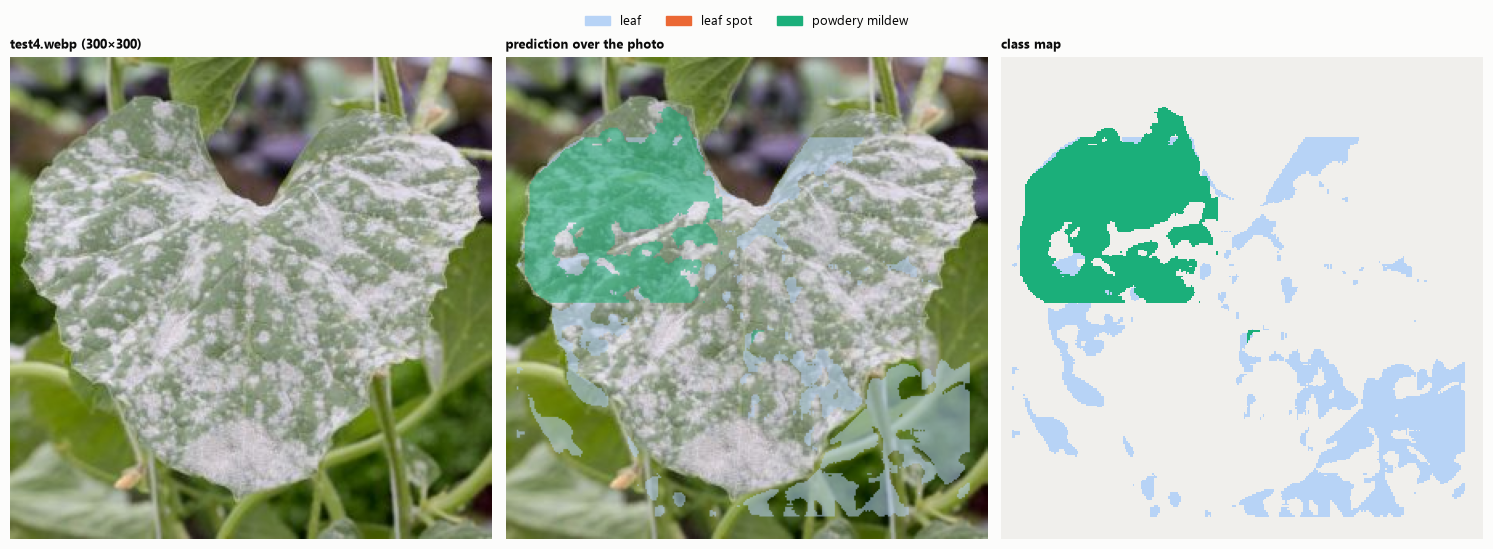

test4.webp: detected 1 leaves, 0 leaf-spot and 3 mildew regions (confidence ≥ thresholds)
  largest leaf (app)  leaf spot 0.0 % (none) | powdery mildew 31.1 % (severe) | healthy 68.9 %
  whole image         leaf spot 0.0 % (none) | powdery mildew 47.4 % (severe) | healthy 52.6 %


In [14]:
PHOTOS = [Path(r"C:\Users\bp67339\Downloads\test4.webp")]

kind, predict, model = load_predictor(CHECKPOINT, cat_names)
OVERLAY = {"leaf": "#b7d3f6", **{d: CLASS_COLOR[d] for d in DISEASES}}
hexrgb = lambda h: np.array([int(h[k:k + 2], 16) for k in (1, 3, 5)], float)

for path in PHOTOS:
    image = Image.open(path).convert("RGB")
    masks, names, conf = predict(image)
    keep = conf >= np.where(names == "leaf", LEAF_CONF, DISEASE_CONF)
    masks, names, conf = masks[keep], names[keep], conf[keep]
    pmap = paint_class_map(masks, names, (image.height, image.width))
    leaf_cov, img_cov = coverage_primary_leaf(masks, names), image_coverage(pmap)

    overlay = np.asarray(image, float).copy()
    for cls in ("leaf", "powdery_mildew", "leaf_spot"):  # same paint order as the class map
        m = pmap == CLASSES.index(cls)
        overlay[m] = 0.45 * overlay[m] + 0.55 * hexrgb(OVERLAY[cls])

    found = {c: int((names == c).sum()) for c in ("leaf", *DISEASES)}
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    axes[0].imshow(image); axes[0].set_title(f"{path.name} ({image.width}×{image.height})", fontsize=9)
    axes[1].imshow(overlay.astype(np.uint8)); axes[1].set_title("prediction over the photo", fontsize=9)
    axes[2].imshow(pmap, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest"); axes[2].set_title("class map", fontsize=9)
    for ax in axes:
        ax.axis("off")
    fig.legend(handles=[Patch(color=OVERLAY[c], label=LABEL[c]) for c in OVERLAY], loc="upper center", ncols=3,
               bbox_to_anchor=(0.5, 1.02))
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(OUT / f"photo_{path.stem}.png", dpi=110)
    plt.show()

    print(f"{path.name}: detected {found['leaf']} leaves, {found['leaf_spot']} leaf-spot and "
          f"{found['powdery_mildew']} mildew regions (confidence ≥ thresholds)")
    for level, cov in (("largest leaf (app)", leaf_cov), ("whole image", img_cov)):
        if cov is None:
            print(f"  {level:<19} no leaf detected")
        else:
            print(f"  {level:<19} " + " | ".join(f"{LABEL[d]} {cov[d]:.1f} % ({sev(cov[d])})" for d in DISEASES) +
                  f" | healthy {100 - sum(cov.values()):.1f} %")

del model, predict
torch.cuda.empty_cache()

## Save the numbers

Writes `metrics.json` with every value above (point estimates and 95 % CIs) so results can be compared across runs.

In [15]:
def ci_dict(point, boots):
    lo, hi = ci(boots)
    return {"value": float(point), "ci95": [float(lo), float(hi)]}


summary = {
    "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "test_data": TEST_NAME, "test_images": n,
    "thresholds": {"leaf": LEAF_CONF, "disease": DISEASE_CONF}, "ms_per_image_gpu": round(MS_PER_IMAGE, 1),
    "pixel": {c: {k: ci_dict(pix[c][k], [b[c][k] for b in pix_boot]) for k in ("precision", "recall", "f1", "iou")}
              for c in CLASSES} | {"accuracy": float(pix["accuracy"]), "miou": ci_dict(pix["miou"], [b["miou"] for b in pix_boot]),
                                   "mf1": ci_dict(pix["mf1"], [b["mf1"] for b in pix_boot])},
    "image": {d: {k: (ci_dict(v, [b[d][k] for b in img_boot]) if isinstance(v, float) else v) for k, v in img_m[d].items()}
              for d in DISEASES},
    "primary_leaf": {d: {k: (float(v) if isinstance(v, float) else v) for k, v in leaf_m[d].items()} for d in DISEASES},
    "threshold_sweep": {str(t): {d: {"pixel_precision": float(p[d]["precision"]), "pixel_recall": float(p[d]["recall"]),
                                     "pixel_iou": float(p[d]["iou"]), "mae_pos": float(im[d]["mae_pos"]),
                                     "bias_pos": float(im[d]["bias_pos"])} for d in DISEASES}
                        for t, (p, im) in sweep.items()},
    "instance": inst,
}
(OUT / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

saved:
  coverage_scatter_bland_altman.png
  examples.png
  instance_map.png
  metrics.json
  photo_test4.png
  pixel_confusion.png
  pixel_metrics.png
  severity_confusion.png
  threshold_sweep.png


## Reading the report

- **Decide by sections 1–3:**
  - MAE on infected images below about 2 pp, bias within ±1 pp;
  - presence recall ≥ 0.9;
  - severity accuracy ≥ 0.9;
  - CCC ≥ 0.85.
- **Section 4 says why.** Precision well above recall for a disease means the masks are too small. The coverage bias is then negative, and a lower threshold (section 5) or a retrain helps.
- **Wide CIs** (few infected test images) mean two models can only be called different if their intervals barely overlap. Use the paired test in `06_backbone_study.ipynb` for that.
- **Compare runs** by running this notebook with another `RUN` and comparing the `metrics.json` files.